---
numbering: false
---

# Download Sentinel-2 Data

In [25]:
import pystac_client
import planetary_computer
import odc.stac

import geopandas as gpd
import rioxarray as rxr
import numpy as np

import matplotlib.pyplot as plt

from shapely import box
from pystac import ItemCollection

## Use `pystac-client` to search for Sentinel-2 data

Set out our search criteria. If you cannot find a suitable image (e.g. your search returns zero items, or those that exist are cloudy) you may have to broaden your search criteria.

In [26]:
# Provide a name for our area of interest (AOI)
aoi_name = "bristol"

# Provide the bounding box coordinates for the AOI in the format [min_lon, min_lat, max_lon, max_lat]
bbox = [-2.76, 51.38,-2.43,51.53]

# Provide the date range for the search in the format "YYYY-MM-DD/YYYY-MM-DD"
daterange = "2026-06-01/2026-08-31"  # summer 2026

# Provide a cloud cover percentage threshold for filtering the search results
max_cloud_percent = 20  # maximum cloud cover percentage

# Filter only to scenes where fractional coverage of bounding box exceeds desired threshold
aoi_fraction_threshold = .7  # 70% minimum

# Provide a 'collection' from the Microsoft Planetary Computer STAC API to search for imagery. 
# For example, "sentinel-2-l2a" for Sentinel-2 Level 2A (Surface Reflectance) data.
# See https://planetarycomputer.microsoft.com/CATALOG for more examples
collection = "sentinel-2-l2a"

Turn our bbox list into a `GeoPandas` dataframe to sanity check we have the correct region:

In [27]:
aoi = gpd.GeoDataFrame(geometry=[box(*bbox)], crs="EPSG:4326")

aoi.explore()

Connect the Microsoft Planetary Computer.

In [28]:
# Connect to the MPC
stac_url = "https://planetarycomputer.microsoft.com/api/stac/v1"

catalog = pystac_client.Client.open(
    stac_url,
    modifier=planetary_computer.sign_inplace,  # only needed for MPC

    )

Search for the dataset according to our search parameters, with an additional `query` sorting the results by cloud cover in ascending order.

In [29]:
# Search for cloud-free Sentinel-2 L2A imagery in Summer
search = catalog.search(
    collections=[collection],
    bbox=bbox,
    datetime=daterange,
    query={
        "eo:cloud_cover": {"lt": max_cloud_percent},  # Cloud cover less than 15%
        }, 
    sortby=[{"field": "properties.eo:cloud_cover", "direction": "asc"}]  # Sort by cloud cover in ascending order
)

# Convert the search result object into a list of `pystac.Item` objects
items = search.item_collection()
print(f"Found {len(items)} matching scene(s).")

Found 30 matching scene(s).


The next cell is a custom script that filters out satellite scenes that only clip the area of interest by a small fraction. The minimum fraction you would like is set by `bbox_fraction_threshold` above (defaults to `0.7`, i.e. 70%).

In [30]:
# convert aoi to a geopandas dataframe
aoi_gdf = gpd.GeoDataFrame(geometry=[box(*bbox)], crs="EPSG:4326")

# convert search results to a geopandas dataframe
search_gdf = gpd.GeoDataFrame.from_features(items.to_dict(), crs="EPSG:4326")

# convert both to an equal area projection (EPSG:8857) so we can work in metres
aoi_gdf = aoi_gdf.to_crs(8857)
search_gdf = search_gdf.to_crs(8857)

# clip search gdf to aoi gdf
search_gdf = search_gdf.clip(aoi_gdf)

# Calculate the fraction of the AOI covered by each scene
search_gdf = search_gdf.sort_index()
search_gdf["frac"] = search_gdf.area / aoi_gdf.area.values[0]

# Include a boolean column indicating whether the scene exceeds the AOI fraction threshold
search_gdf["exceed_frac"] = np.where(search_gdf["frac"].values >= aoi_fraction_threshold, True, False)

# Reconstruct the ItemCollection with only the items that exceed the AOI fraction threshold
items_list = []
for i, exceed_frac in zip(items, search_gdf.exceed_frac.values):
    if exceed_frac == True:
        items_list.append(i)

items = ItemCollection(items=items_list)
print(f"Afer AOI filtering, returns {len(items)} Items")

Afer AOI filtering, returns 15 Items


If you cannot find any items after searching, you may have to broaden your search parameters.

## Downloading data with `odc-stac`

Select the first item (or edit the index number to select another if this one isn't suitable).

In [31]:
item = items[0]

date = item.properties['datetime'][:10]
epsg = item.properties['proj:code']
satellite = item.properties['platform']

print(f"Selected Scene ID: {item.id}")
print(f"Acquisition Date: {item.properties['datetime']}")
print(f"Cloud Cover: {item.properties['eo:cloud_cover']}%")
print(f"Projection: {item.properties['proj:code']}")

Selected Scene ID: S2C_MSIL2A_20260624T110621_R137_T30UWC_20260624T144908
Acquisition Date: 2026-06-24T11:06:21.025000Z
Cloud Cover: 0.164893%
Projection: EPSG:32630


Select the Sentinel-2 bands we want, and use `odc.stac.load()` to load our data. 

In [32]:
# Requested bands - I've commented out some we don't need for now, but you can uncomment them if you want to use them later
bands = [
    # 'coastal',  # band 1, coastal/aerosol
    'blue',  # band 2, blue
    'green',  # band 3, green
    'red',  # band 4, red
    'nir',  # band 8, near-infrared
    # 'swir16',  # band 11, shortwave infrared 1
    # 'swir22',  # band 12, shortwave infrared 2
]

# Load requested bands directly into an xarray.Dataset using odc-stac
ds = odc.stac.load(
    [item],
    bands=bands,
    bbox=bbox,
    # crs="EPSG:XXXX",  # Uncomment if you want a different projection: by default, will use the native CRS
    # resolution=100, # Uncomment if you want a different resolution: by default, will use the native resolution of the imagery
).squeeze()

# xarray is 'lazy' by default, meaning it doesn't load the data into memory until you explicitly ask for it.
# The `.compute()` method forces the data to be loaded into memory, which can take some time depending on the size of the dataset.
ds.compute()

<xarray.Dataset> Size: 62MB
Dimensions:      (y: 1681, x: 2303)
Coordinates:
  * y            (y) float64 13kB 5.709e+06 5.709e+06 ... 5.692e+06 5.692e+06
  * x            (x) float64 18kB 5.166e+05 5.167e+05 ... 5.397e+05 5.397e+05
    spatial_ref  int32 4B 32630
    time         datetime64[ns] 8B 2026-06-24T11:06:21.025000
Data variables:
    blue         (y, x) float32 15MB 1.673e+03 1.656e+03 ... 1.296e+03 1.28e+03
    green        (y, x) float32 15MB 1.959e+03 1.939e+03 ... 1.732e+03 1.847e+03
    red          (y, x) float32 15MB 2.122e+03 2.124e+03 ... 1.468e+03 1.405e+03
    nir          (y, x) float32 15MB 1.794e+03 1.804e+03 ... 5.99e+03 6.415e+03

Convert to a `band` dimension and add appropriate attribute names. Also, convert to surface refelctance.

In [33]:
# stack variables into a band dimension
ds = ds.to_array(dim="band").squeeze()

# add the band names as a long_name attribute to the dataset
ds.attrs["long_name"] = list(ds["band"].values)


# Surface reflectance scaling for sentinel-2
ds = ds / 10000.0

# Visualise
ds

<xarray.DataArray (band: 4, y: 1681, x: 2303)> Size: 62MB
array([[[0.1673, 0.1656, 0.1612, ..., 0.21  , 0.192 , 0.1861],
        [0.1678, 0.1671, 0.1671, ..., 0.1992, 0.1791, 0.2012],
        [0.1685, 0.1627, 0.1663, ..., 0.1659, 0.1567, 0.1727],
        ...,
        [0.1603, 0.1623, 0.1601, ..., 0.1447, 0.1393, 0.1259],
        [0.16  , 0.1615, 0.1637, ..., 0.1456, 0.1319, 0.1261],
        [0.1617, 0.1617, 0.1635, ..., 0.1521, 0.1296, 0.128 ]],

       [[0.1959, 0.1939, 0.195 , ..., 0.227 , 0.2188, 0.207 ],
        [0.1966, 0.1926, 0.1941, ..., 0.2146, 0.2031, 0.2139],
        [0.196 , 0.1938, 0.195 , ..., 0.1991, 0.1837, 0.1864],
        ...,
        [0.1961, 0.2003, 0.2003, ..., 0.1909, 0.1856, 0.1815],
        [0.1983, 0.2036, 0.2011, ..., 0.1905, 0.1797, 0.1819],
        [0.1971, 0.1997, 0.2   , ..., 0.1876, 0.1732, 0.1847]],

       [[0.2122, 0.2124, 0.2138, ..., 0.2472, 0.231 , 0.2197],
        [0.2157, 0.211 , 0.2149, ..., 0.226 , 0.218 , 0.2112],
        [0.2163, 0.2132, 0.2144, ..., 0.2008, 0.197 , 0.2042],
        ...,
        [0.2333, 0.2337, 0.2394, ..., 0.1843, 0.1582, 0.1399],
        [0.2389, 0.2398, 0.2425, ..., 0.1801, 0.1523, 0.1411],
        [0.2335, 0.2367, 0.2398, ..., 0.1733, 0.1468, 0.1405]],

       [[0.1794, 0.1804, 0.1815, ..., 0.3041, 0.3406, 0.3426],
        [0.1815, 0.1815, 0.1817, ..., 0.2869, 0.2957, 0.3128],
        [0.1807, 0.1811, 0.1817, ..., 0.328 , 0.2975, 0.2847],
        ...,
        [0.3211, 0.3321, 0.3284, ..., 0.4848, 0.5475, 0.6278],
        [0.32  , 0.3286, 0.3295, ..., 0.4806, 0.5756, 0.6376],
        [0.3153, 0.3257, 0.3252, ..., 0.4743, 0.599 , 0.6415]]],
      shape=(4, 1681, 2303), dtype=float32)
Coordinates:
  * band         (band) object 32B 'blue' 'green' 'red' 'nir'
  * y            (y) float64 13kB 5.709e+06 5.709e+06 ... 5.692e+06 5.692e+06
  * x            (x) float64 18kB 5.166e+05 5.167e+05 ... 5.397e+05 5.397e+05
    spatial_ref  int32 4B 32630
    time         datetime64[ns] 8B 2026-06-24T11:06:21.025000
Attributes:
    long_name:  ['blue', 'green', 'red', 'nir']

Visualise to check the image has good coverage and quality. If it isn't appropriate, you can explore a different `item` above (e.g. `item = items[3]`).

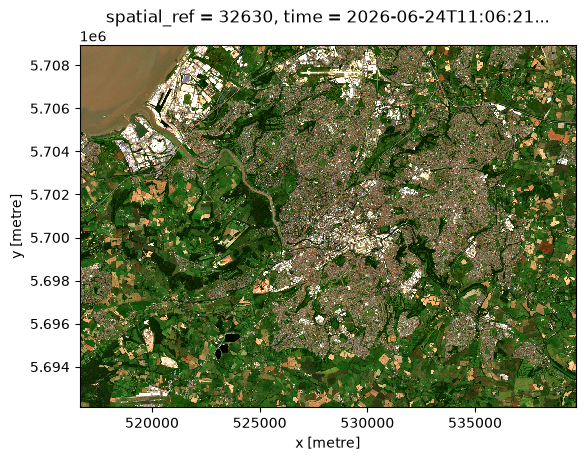

In [34]:
rgb = ds.sel(band=["red", "green", "blue"])

fig, ax = plt.subplots()
rgb.plot.imshow(ax=ax, robust=True)
ax.set_aspect("equal")

Save this under a sensible name, auto-generated from parameters:

In [18]:
filename = f"{aoi_name}_{date}_{satellite}.tif"

print('Saving to:', filename)

ds.rio.to_raster(filename, driver="GTiff", compress="deflate")

Saving to: bristol_2026-08-13_Sentinel-2C.tif


An example of how to load the data:

In [19]:
ds_loaded = rxr.open_rasterio(filename, masked=True).squeeze()

ds_loaded['band'] = list(ds_loaded.attrs["long_name"])

ds_loaded

<xarray.DataArray (band: 4, y: 1681, x: 2303)> Size: 62MB
array([[[   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        ...,
        [0.1478, 0.1464, 0.1483, ..., 0.1782, 0.1876, 0.1983],
        [0.1449, 0.1473, 0.1487, ..., 0.1785, 0.178 , 0.2014],
        [0.1491, 0.1509, 0.1488, ..., 0.1768, 0.1812, 0.2072]],

       [[   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        ...,
        [0.1748, 0.174 , 0.1764, ..., 0.2098, 0.2332, 0.2436],
        [0.177 , 0.1782, 0.1778, ..., 0.2113, 0.2206, 0.2469],
        [0.1778, 0.1778, 0.1754, ..., 0.2151, 0.2249, 0.2516]],

       [[   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        ...,
        [0.1704, 0.1682, 0.1711, ..., 0.2561, 0.286 , 0.3164],
        [0.1657, 0.1671, 0.1699, ..., 0.2503, 0.2718, 0.3207],
        [0.1665, 0.1721, 0.1728, ..., 0.2455, 0.2818, 0.3289]],

       [[   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        ...,
        [0.413 , 0.4206, 0.4184, ..., 0.4337, 0.4667, 0.4909],
        [0.444 , 0.443 , 0.4306, ..., 0.4271, 0.4757, 0.4891],
        [0.446 , 0.432 , 0.4223, ..., 0.4298, 0.4906, 0.4924]]],
      shape=(4, 1681, 2303), dtype=float32)
Coordinates:
  * band         (band) object 32B 'blue' 'green' 'red' 'nir'
  * y            (y) float64 13kB 5.709e+06 5.709e+06 ... 5.692e+06 5.692e+06
  * x            (x) float64 18kB 5.166e+05 5.167e+05 ... 5.397e+05 5.397e+05
    spatial_ref  int32 4B 32630
    time         datetime64[ns] 8B 2026-08-13T11:06:21.025000
Attributes:
    long_name:  ['blue', 'green', 'red', 'nir']